# Evaluación Sumativa 1 — Análisis exploratorio e inferencial
## Dataset: Framingham Heart Study (riesgo de enfermedad coronaria a 10 años)

**MCDI501:** Estadística Computacional para la Toma de Decisiones
**Fase 2:** Búsqueda y recopilación de información

| | |
|---|---|
| **Integrantes** | Brian Cerda · Kattia Espinoza · Karla Martínez · Christopher Ulloa |
| **Docente** | «nombre del docente» |
| **Fecha** | «dd/mm/aaaa» |
| **Repositorio** | «https://github.com/usuario/repositorio» |
| **Dataset** | *Logistic regression To predict heart disease* (Kaggle), archivo `framingham.csv` |

Este cuaderno acompaña nuestro informe técnico y contiene el código completo y reproducible. Sigue el mismo orden del
informe: preparación y calidad de los datos, análisis exploratorio, estimación de parámetros y pruebas de hipótesis.
Las tablas y figuras numeradas son las mismas que aparecen en el informe; los gráficos marcados como
*complementarios* apoyan el análisis, pero no se incluyen en él. La semilla se fija en 42 para que los resultados se
puedan reproducir.

## Introducción

Las enfermedades cardiovasculares son una de las principales causas de muerte en el mundo, y una parte importante de
ellas se puede prevenir si se identifica a tiempo a las personas en riesgo. Nuestro problema es de **decisión bajo
incertidumbre**: a partir de información que se puede medir hoy en un control de salud (edad, presión arterial,
colesterol, hábitos y antecedentes), buscamos determinar qué características se asocian a desarrollar enfermedad
coronaria (CHD) en los próximos 10 años, para decidir a quién priorizar en prevención.

**Pregunta de investigación:** ¿qué factores demográficos, conductuales y clínicos se asocian con el desarrollo de
enfermedad coronaria a 10 años, y en qué magnitud?

En esta fase caracterizamos los datos, estimamos parámetros de la población con intervalos de confianza y contrastamos
hipótesis sobre factores de riesgo concretos. Los resultados serán la base del modelo predictivo de las fases siguientes.

---
## 0. Configuración y carga de datos

### 0.1 Librerías

Importamos al inicio todas las librerías que usaremos, para que las dependencias del cuaderno queden visibles en un
solo lugar: `numpy` y `pandas` para manipular los datos, `scipy.stats` para distribuciones y pruebas, `statsmodels`
para intervalos de proporciones y el análisis estratificado, `matplotlib` y `seaborn` para los gráficos, y `pathlib`
para manejar rutas de archivos que funcionen igual en el computador de cada integrante.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.contingency_tables import StratifiedTable

print("Versiones -> pandas:", pd.__version__, "| numpy:", np.__version__)

Versiones -> pandas: 3.0.5 | numpy: 2.5.3


Las librerías se cargaron correctamente. Dejamos registro de las versiones porque, si un integrante obtiene un resultado
distinto, lo primero que conviene revisar es si trabaja con otra versión.

### 0.2 Parámetros del análisis y estilo de los gráficos

Definimos en un solo lugar la semilla, el nivel de significancia, el nivel de confianza y las rutas de trabajo. Así,
si necesitamos cambiar un parámetro, lo modificamos aquí y no en distintas partes del código, lo que evita
inconsistencias y garantiza la reproducibilidad. También fijamos una paleta propia: azul para las personas sin CHD y
naranjo para quienes la desarrollan, que mantenemos en todos los gráficos.

In [2]:
# --- Parámetros del análisis ---
SEMILLA = 42
ALFA = 0.05                  # nivel de significancia de las pruebas
NIVEL_CONFIANZA = 0.95       # nivel de confianza de los intervalos
RUTA_DATOS = Path("data") / "framingham.csv"
CARPETA_FIGURAS = Path("figuras")
CARPETA_TABLAS = Path("tablas")
CARPETA_FIGURAS.mkdir(exist_ok=True)
CARPETA_TABLAS.mkdir(exist_ok=True)

np.random.seed(SEMILLA)
Z_CRITICO = stats.norm.ppf(1 - (1 - NIVEL_CONFIANZA) / 2)   # 1,96 para 95 %

# --- Paleta y estilo propios ---
COLOR_SIN_CHD = "#2a78d6"    # azul: personas sin CHD a 10 años
COLOR_CON_CHD = "#eb6834"    # naranjo: personas con CHD a 10 años
COLOR_TEXTO = "#3d3d3a"
COLOR_REFERENCIA = "#8a8984"
PALETA_OBJETIVO = {0: COLOR_SIN_CHD, 1: COLOR_CON_CHD}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.titlelocation": "left", "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "text.color": COLOR_TEXTO, "axes.labelcolor": COLOR_TEXTO,
    "xtick.color": COLOR_TEXTO, "ytick.color": COLOR_TEXTO,
})
pd.set_option("display.float_format", lambda valor: f"{valor:,.3f}")


def guardar_figura(figura: plt.Figure, nombre: str) -> None:
    """Guarda la figura en la carpeta de figuras para usarla en el informe."""
    figura.savefig(CARPETA_FIGURAS / f"{nombre}.png", bbox_inches="tight")


def guardar_tabla(tabla: pd.DataFrame, nombre: str) -> None:
    """Exporta la tabla a CSV para que el informe use exactamente los resultados de esta ejecución."""
    tabla.to_csv(CARPETA_TABLAS / f"{nombre}.csv", encoding="utf-8")


print(f"Semilla: {SEMILLA} | α = {ALFA} | confianza = {NIVEL_CONFIANZA:.0%} | z crítico = {Z_CRITICO:.3f}")

Semilla: 42 | α = 0.05 | confianza = 95% | z crítico = 1.960


Quedaron definidos α = 0,05 y un nivel de confianza del 95 % (z crítico = 1,96). Los gráficos del informe se guardan
automáticamente en la carpeta `figuras/` y las tablas en la carpeta `tablas/` (formato CSV), de modo que el informe
se construye directamente con los resultados de esta ejecución.

### 0.3 Carga del dataset

Leemos el archivo y traducimos los nombres de las columnas al español. Los nombres originales vienen abreviados en
inglés (`sysBP`, `prevalentHyp`), lo que dificulta la lectura del código y de las tablas. Conservamos el diccionario de
equivalencias para mantener la trazabilidad con la fuente original.

In [3]:
NOMBRES_EN_ESPANOL = {
    "male": "sexo_masculino", "age": "edad", "education": "educacion",
    "currentSmoker": "fumador_actual", "cigsPerDay": "cigarrillos_dia",
    "BPMeds": "medicamento_presion", "prevalentStroke": "acv_previo",
    "prevalentHyp": "hipertension", "diabetes": "diabetes",
    "totChol": "colesterol_total", "sysBP": "presion_sistolica",
    "diaBP": "presion_diastolica", "BMI": "imc", "heartRate": "frecuencia_cardiaca",
    "glucose": "glucosa", "TenYearCHD": "chd_10_anios",
}

datos_originales = pd.read_csv(RUTA_DATOS)
datos = datos_originales.rename(columns=NOMBRES_EN_ESPANOL)

assert datos.columns.size == len(NOMBRES_EN_ESPANOL), "Faltan columnas por renombrar"
print(f"Filas: {datos.shape[0]:,} | Columnas: {datos.shape[1]}")
datos.head()

Filas: 4,238 | Columnas: 16


,sexo_masculino,edad,educacion,fumador_actual,cigarrillos_dia,medicamento_presion,acv_previo,hipertension,diabetes,colesterol_total,presion_sistolica,presion_diastolica,imc,frecuencia_cardiaca,glucosa,chd_10_anios
0,1,39,4.000,0,0.000,0.000,0,0,0,195.000,106.000,70.000,26.970,80.000,77.000,0
1,0,46,2.000,0,0.000,0.000,0,0,0,250.000,121.000,81.000,28.730,95.000,76.000,0
2,1,48,1.000,1,20.000,0.000,0,0,0,245.000,127.500,80.000,25.340,75.000,70.000,0
3,0,61,3.000,1,30.000,0.000,0,1,0,225.000,150.000,95.000,28.580,65.000,103.000,1
4,0,46,3.000,1,23.000,0.000,0,0,0,285.000,130.000,84.000,23.100,85.000,85.000,0


El conjunto contiene **4.238 personas y 16 variables**. Cada fila describe a una persona al inicio del seguimiento
(edad, presión, colesterol, hábitos y diagnósticos) e indica si desarrolló enfermedad coronaria en los 10 años
siguientes (`chd_10_anios`). Como cada registro mide los factores antes de que ocurra o no la enfermedad, los datos
permiten estudiar qué características previas se asocian al riesgo futuro.

---
## 1. Preparación y calidad de los datos

Antes de analizar, necesitamos saber con qué calidad de información trabajamos. En esta sección revisamos la
estructura, los tipos de variable, los datos faltantes, los duplicados, las inconsistencias y los valores atípicos, y
documentamos cada decisión de limpieza.

### 1.1 Estructura, tipos de variables y diccionario de datos

La ficha del dataset en Kaggle describe las variables solo de forma general y no indica qué representa cada nivel de
educación. Para precisar las definiciones revisamos la documentación oficial de la base docente del Framingham Heart
Study, publicada por el National Heart, Lung, and Blood Institute (NHLBI, 2021). Con ella construimos el diccionario de
datos (Tabla 1). Además, comparamos el tipo con que `pandas` almacena cada columna con su tipo estadístico real. La distinción es importante
porque varias variables están codificadas con 0 y 1 (por ejemplo, `hipertension`) y `pandas` las trata como números,
aunque en realidad son categorías. El tipo estadístico determina qué medidas, gráficos y pruebas corresponde aplicar.

In [4]:
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   sexo_masculino       4238 non-null   int64  
 1   edad                 4238 non-null   int64  
 2   educacion            4133 non-null   float64
 3   fumador_actual       4238 non-null   int64  
 4   cigarrillos_dia      4209 non-null   float64
 5   medicamento_presion  4185 non-null   float64
 6   acv_previo           4238 non-null   int64  
 7   hipertension         4238 non-null   int64  
 8   diabetes             4238 non-null   int64  
 9   colesterol_total     4188 non-null   float64
 10  presion_sistolica    4238 non-null   float64
 11  presion_diastolica   4238 non-null   float64
 12  imc                  4219 non-null   float64
 13  frecuencia_cardiaca  4237 non-null   float64
 14  glucosa              3850 non-null   float64
 15  chd_10_anios         4238 non-null   int64  
dtyp

In [5]:
VARIABLES_NUMERICAS = ["edad", "cigarrillos_dia", "colesterol_total", "presion_sistolica",
                       "presion_diastolica", "imc", "frecuencia_cardiaca", "glucosa"]
VARIABLES_BINARIAS = ["sexo_masculino", "fumador_actual", "medicamento_presion",
                      "acv_previo", "hipertension", "diabetes"]
VARIABLES_ORDINALES = ["educacion"]
VARIABLE_OBJETIVO = "chd_10_anios"
VARIABLES_CATEGORICAS = VARIABLES_BINARIAS + VARIABLES_ORDINALES

assert set(VARIABLES_NUMERICAS + VARIABLES_CATEGORICAS + [VARIABLE_OBJETIVO]) == set(datos.columns)

# Tabla 1. Diccionario de las variables (fuente: documentación NHLBI y ficha de Kaggle)
# Cada entrada: (descripción, tipo estadístico, unidad o escala)
DICCIONARIO = {
    "sexo_masculino": ("Sexo del participante (en la base original 1 = hombre, 2 = mujer; recodificado a 1/0)",
                       "Cualitativa nominal (binaria)", "1 = hombre, 0 = mujer"),
    "edad": ("Edad al momento del examen", "Cuantitativa continua", "Años cumplidos (32–70)"),
    "educacion": ("Nivel educativo alcanzado", "Cualitativa ordinal",
                  "1 = 0 a 11 años de estudio; 2 = secundaria completa o GED; "
                  "3 = estudios superiores incompletos o formación técnica; 4 = título universitario o más"),
    "fumador_actual": ("Fuma cigarrillos al momento del examen", "Cualitativa nominal (binaria)", "0 = no, 1 = sí"),
    "cigarrillos_dia": ("Cigarrillos fumados al día (0 en no fumadores)", "Cuantitativa discreta", "Cigarrillos/día"),
    "medicamento_presion": ("Usa medicamentos antihipertensivos al momento del examen",
                            "Cualitativa nominal (binaria)", "0 = no, 1 = sí"),
    "acv_previo": ("Antecedente de accidente cerebrovascular", "Cualitativa nominal (binaria)", "0 = no, 1 = sí"),
    "hipertension": ("Hipertensión prevalente: en tratamiento, o con PAS ≥ 140 o PAD ≥ 90 mmHg en un segundo examen",
                     "Cualitativa nominal (binaria)", "0 = no, 1 = sí"),
    "diabetes": ("Diabetes: en tratamiento o con glucosa casual ≥ 200 mg/dL",
                 "Cualitativa nominal (binaria)", "0 = no, 1 = sí"),
    "colesterol_total": ("Colesterol total en sangre (sérico)", "Cuantitativa continua", "mg/dL"),
    "presion_sistolica": ("Presión sistólica (promedio de las dos últimas de tres mediciones)",
                          "Cuantitativa continua", "mmHg"),
    "presion_diastolica": ("Presión diastólica (promedio de las dos últimas de tres mediciones)",
                           "Cuantitativa continua", "mmHg"),
    "imc": ("Índice de masa corporal: peso / talla²", "Cuantitativa continua", "kg/m²"),
    "frecuencia_cardiaca": ("Frecuencia cardíaca (ventricular)", "Cuantitativa discreta", "Latidos/min"),
    "glucosa": ("Glucosa en sangre medida sin ayuno (casual)", "Cuantitativa continua", "mg/dL"),
    "chd_10_anios": ("Desarrolló enfermedad coronaria en los 10 años siguientes al examen",
                     "Cualitativa nominal (binaria)", "0 = no, 1 = sí"),
}
assert set(DICCIONARIO) == set(datos.columns), "El diccionario no cubre todas las variables"

diccionario_variables = pd.DataFrame.from_dict(
    DICCIONARIO, orient="index", columns=["descripcion", "tipo", "unidad_o_escala"]
).loc[datos.columns]
diccionario_variables.insert(0, "nombre_original",
                             {nuevo: original for original, nuevo in NOMBRES_EN_ESPANOL.items()})
diccionario_variables["rol"] = np.where(diccionario_variables.index == VARIABLE_OBJETIVO, "Respuesta", "Predictora")
diccionario_variables["tipo_en_pandas"] = datos.dtypes.astype(str)
guardar_tabla(diccionario_variables, "tabla_01_diccionario")
diccionario_variables

,nombre_original,descripcion,tipo,unidad_o_escala,rol,tipo_en_pandas
sexo_masculino,male,Sexo del participante (en la base original 1 =...,Cualitativa nominal (binaria),"1 = hombre, 0 = mujer",Predictora,int64
edad,age,Edad al momento del examen,Cuantitativa continua,Años cumplidos (32–70),Predictora,int64
educacion,education,Nivel educativo alcanzado,Cualitativa ordinal,1 = 0 a 11 años de estudio; 2 = secundaria com...,Predictora,float64
fumador_actual,currentSmoker,Fuma cigarrillos al momento del examen,Cualitativa nominal (binaria),"0 = no, 1 = sí",Predictora,int64
cigarrillos_dia,cigsPerDay,Cigarrillos fumados al día (0 en no fumadores),Cuantitativa discreta,Cigarrillos/día,Predictora,float64
medicamento_presion,BPMeds,Usa medicamentos antihipertensivos al momento ...,Cualitativa nominal (binaria),"0 = no, 1 = sí",Predictora,float64
acv_previo,prevalentStroke,Antecedente de accidente cerebrovascular,Cualitativa nominal (binaria),"0 = no, 1 = sí",Predictora,int64
hipertension,prevalentHyp,"Hipertensión prevalente: en tratamiento, o con...",Cualitativa nominal (binaria),"0 = no, 1 = sí",Predictora,int64
diabetes,diabetes,Diabetes: en tratamiento o con glucosa casual ...,Cualitativa nominal (binaria),"0 = no, 1 = sí",Predictora,int64
colesterol_total,totChol,Colesterol total en sangre (sérico),Cuantitativa continua,mg/dL,Predictora,float64


De las 16 variables, solo 8 son cuantitativas: edad, cigarrillos por día, colesterol, presión
sistólica y diastólica, IMC, frecuencia cardíaca y glucosa. Las otras 8 son categóricas: siete binarias, incluida la
variable objetivo, y una ordinal (educación). Algunas binarias aparecen como `float64` solo porque tienen datos
faltantes. En consecuencia, a las numéricas les aplicaremos medidas de tendencia central y dispersión, y a las
categóricas, frecuencias y tasas de enfermedad por categoría.

La revisión de la documentación aporta tres precisiones importantes para interpretar los resultados:

- **Origen de los datos.** El dataset coincide con la base docente del NHLBI en variables, unidades y rangos (por
  ejemplo, colesterol entre 107 y 696 mg/dL y presión sistólica entre 83,5 y 295 mmHg). Corresponde al primer ciclo de
  examen, realizado desde aproximadamente 1956, sin las personas que ya tenían enfermedad coronaria. Por eso
  `chd_10_anios` registra **casos nuevos** de la enfermedad, y los factores se midieron antes de que esta ocurriera.
- **Definiciones clínicas.** La hipertensión y la diabetes no son autorreportes. La hipertensión exige tratamiento o
  presión alta confirmada en un segundo examen, y la diabetes, tratamiento o glucosa casual de 200 mg/dL o más.
- **Variable objetivo.** Kaggle no documenta cómo se construyó `chd_10_anios`. Según la documentación oficial, la
  enfermedad coronaria incluye angina de pecho, infarto de miocardio, insuficiencia coronaria (angina inestable) y
  muerte por enfermedad coronaria.

### 1.2 Datos faltantes

Cuantificamos los valores faltantes por variable y verificamos si su ausencia se relaciona con la enfermedad. Los
faltantes reducen la información disponible y, si se concentran en un tipo de persona (por ejemplo, en quienes
enferman), pueden sesgar las conclusiones. El porcentaje de faltantes se grafica en la Figura 1b (sección 2.2).

In [6]:
tabla_faltantes = pd.DataFrame({
    "faltantes": datos.isna().sum(),
    "porcentaje": datos.isna().mean() * 100,
}).query("faltantes > 0").sort_values("faltantes", ascending=False)

filas_incompletas = datos.isna().any(axis=1).sum()
print(f"Filas con al menos un faltante: {filas_incompletas:,} ({filas_incompletas / len(datos):.1%} del total)")
guardar_tabla(tabla_faltantes, "anexo_faltantes")
tabla_faltantes

Filas con al menos un faltante: 582 (13.7% del total)


,faltantes,porcentaje
glucosa,388,9.155
educacion,105,2.478
medicamento_presion,53,1.251
colesterol_total,50,1.180
cigarrillos_dia,29,0.684
imc,19,0.448
frecuencia_cardiaca,1,0.024


In [7]:
# ¿La falta del dato de glucosa se relaciona con la enfermedad?
falta_glucosa = datos["glucosa"].isna()
print(f"% con CHD cuando FALTA la glucosa:    {datos.loc[falta_glucosa, VARIABLE_OBJETIVO].mean():.1%}")
print(f"% con CHD cuando HAY dato de glucosa: {datos.loc[~falta_glucosa, VARIABLE_OBJETIVO].mean():.1%}")

% con CHD cuando FALTA la glucosa:    12.9%
% con CHD cuando HAY dato de glucosa: 15.4%


582 registros (13,7 %) tienen al menos un dato faltante, pero el problema se concentra en la **glucosa, con 388
faltantes (9,2 %)**. Ninguna otra variable supera el 2,5 %, y las variables centrales para nuestra pregunta (edad,
sexo, presión arterial, hipertensión, tabaquismo y la variable objetivo) están completas.

La tasa de CHD es de 12,9 % entre quienes no tienen el dato de glucosa y de 15,4 % entre quienes sí lo tienen. Si la
falta del dato estuviera ligada a la enfermedad, esperaríamos una diferencia grande; como es pequeña, consideramos
razonable suponer que los faltantes ocurren al azar. Por lo tanto, trabajar con los casos completos no debería sesgar
de forma importante los resultados de esta fase.

### 1.3 Registros duplicados

Buscamos filas idénticas en todas sus columnas, porque un duplicado contaría dos veces a la misma persona y
distorsionaría frecuencias, medias y pruebas.

In [8]:
cantidad_duplicados = datos.duplicated().sum()
print(f"Filas duplicadas: {cantidad_duplicados}")

Filas duplicadas: 0


No hay filas duplicadas. Cada registro corresponde a una persona distinta, lo que además respalda el supuesto de
independencia de las observaciones que exigen las pruebas de hipótesis de la sección 4.

### 1.4 Inconsistencias lógicas

Un valor puede estar dentro de un rango razonable y, aun así, contradecir a otra variable. Por eso revisamos reglas que
los datos deberían cumplir por sentido común o por definición clínica, como que un no fumador no declare cigarrillos o
que la presión sistólica sea mayor que la diastólica.

In [9]:
reglas_de_consistencia = {
    "No fumador con cigarrillos > 0":
        (datos["fumador_actual"] == 0) & (datos["cigarrillos_dia"] > 0),
    "Fumador con cigarrillos = 0":
        (datos["fumador_actual"] == 1) & (datos["cigarrillos_dia"] == 0),
    "Fumador sin dato de cigarrillos":
        (datos["fumador_actual"] == 1) & datos["cigarrillos_dia"].isna(),
    "Presión sistólica <= diastólica":
        datos["presion_sistolica"] <= datos["presion_diastolica"],
    "Usa medicamento para la presión sin ser hipertenso":
        (datos["medicamento_presion"] == 1) & (datos["hipertension"] == 0),
    "No hipertenso con presión medida >= 140/90":
        (datos["hipertension"] == 0)
        & ((datos["presion_sistolica"] >= 140) | (datos["presion_diastolica"] >= 90)),
    "Binarias con valores distintos de 0 y 1":
        ~datos[VARIABLES_BINARIAS + [VARIABLE_OBJETIVO]].isin([0, 1, np.nan]).all(axis=1),
}
tabla_inconsistencias = pd.DataFrame(
    {"casos": {regla: int(condicion.sum()) for regla, condicion in reglas_de_consistencia.items()}}
)
tabla_inconsistencias

,casos
No fumador con cigarrillos > 0,0
Fumador con cigarrillos = 0,0
Fumador sin dato de cigarrillos,29
Presión sistólica <= diastólica,0
Usa medicamento para la presión sin ser hipertenso,0
No hipertenso con presión medida >= 140/90,318
Binarias con valores distintos de 0 y 1,0


No encontramos contradicciones lógicas: ningún no fumador declara cigarrillos, ninguna presión sistólica es menor que la
diastólica, todos los que usan medicamentos para la presión están clasificados como hipertensos y las variables
binarias solo toman los valores 0 y 1.

Sí aparecen dos situaciones a considerar. Los **29 fumadores sin dato de cigarrillos** son un faltante, no un error.
Las **318 personas sin diagnóstico de hipertensión, pero con una presión medida de 140/90 o más**, no las tratamos como
error. Según la documentación oficial (Tabla 1), el diagnóstico exige tratamiento o presión alta confirmada en un
segundo examen, de modo que una medición alta aislada no basta. Sin embargo, este hallazgo es relevante para
nuestra pregunta: indica que el diagnóstico de hipertensión podría subestimar la presión alta real de la población.
Por eso, en las pruebas de hipótesis analizamos tanto la presión medida como el diagnóstico.

### 1.5 Valores atípicos y asimetría

Identificamos valores atípicos con el criterio de Tukey (bajo Q1 − 1,5·RIC o sobre Q3 + 1,5·RIC) y medimos la
asimetría de cada variable numérica. Los atípicos y las colas largas alteran la media y la desviación estándar, por lo
que este paso nos indica en qué variables conviene usar medidas robustas, como la mediana, y nos obliga a decidir si
cada valor extremo es un error o un caso real.

In [10]:
def resumen_atipicos(serie: pd.Series) -> pd.Series:
    """Calcula límites de Tukey, cantidad de atípicos y asimetría de una variable numérica."""
    serie = serie.dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    rango_intercuartil = q3 - q1
    limite_inferior = q1 - 1.5 * rango_intercuartil
    limite_superior = q3 + 1.5 * rango_intercuartil
    atipicos = ((serie < limite_inferior) | (serie > limite_superior)).sum()
    return pd.Series({
        "minimo": serie.min(), "maximo": serie.max(),
        "limite_inferior": limite_inferior, "limite_superior": limite_superior,
        "atipicos": atipicos, "porcentaje_atipicos": atipicos / serie.size * 100,
        "asimetria": serie.skew(),
    })

tabla_atipicos = datos[VARIABLES_NUMERICAS].apply(resumen_atipicos).T
guardar_tabla(tabla_atipicos, "anexo_atipicos")
tabla_atipicos

,minimo,maximo,limite_inferior,limite_superior,atipicos,porcentaje_atipicos,asimetria
edad,32.000,70.000,21.000,77.000,0.000,0.000,0.228
cigarrillos_dia,0.000,70.000,-30.000,50.000,12.000,0.285,1.248
colesterol_total,107.000,696.000,120.500,348.500,56.000,1.337,0.871
presion_sistolica,83.500,295.000,76.500,184.500,126.000,2.973,1.145
presion_diastolica,48.000,142.500,52.688,112.188,81.000,1.911,0.714
imc,15.540,56.800,15.615,35.495,97.000,2.299,0.982
frecuencia_cardiaca,44.000,143.000,45.500,105.500,76.000,1.794,0.644
glucosa,40.000,394.000,47.000,111.000,188.000,4.883,6.213


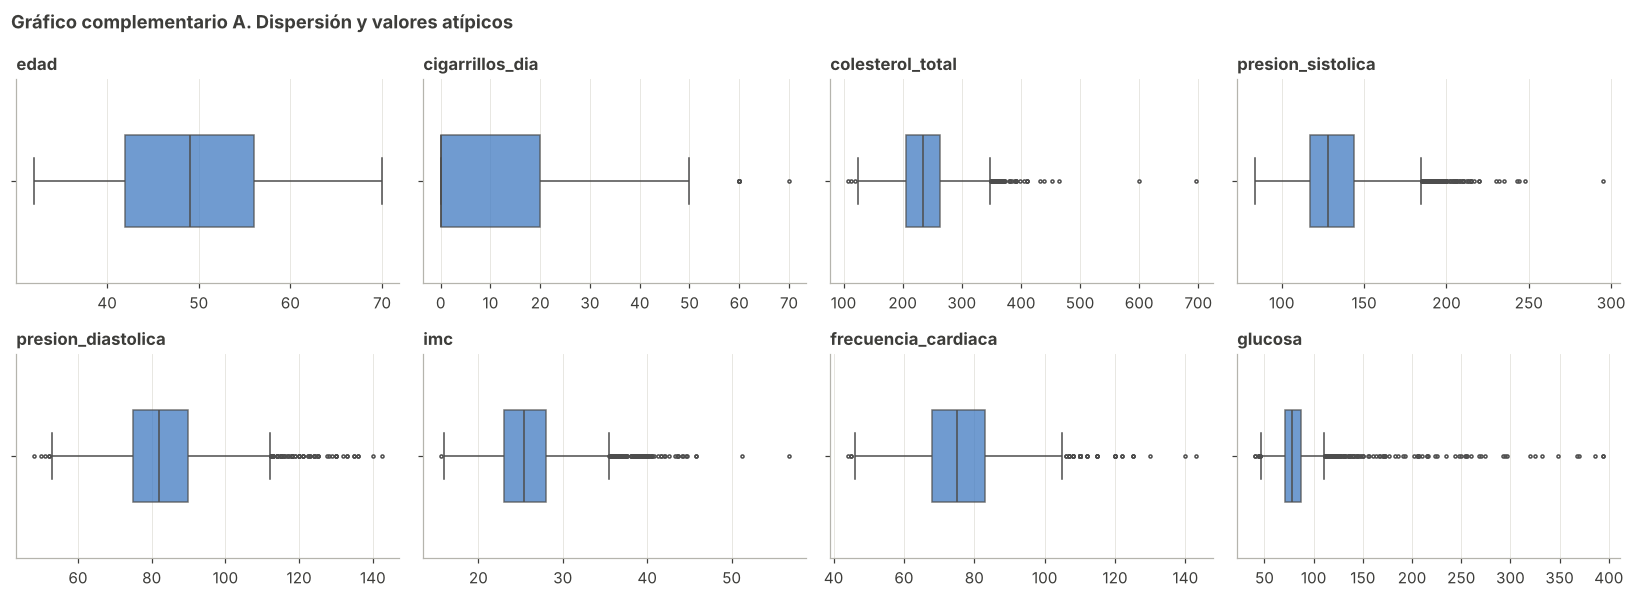

In [11]:
# Gráfico complementario A: diagramas de caja de las variables numéricas
figura, ejes = plt.subplots(2, 4, figsize=(15, 5.5))
for eje, variable in zip(ejes.flat, VARIABLES_NUMERICAS):
    sns.boxplot(x=datos[variable], color=COLOR_SIN_CHD, width=0.45, fliersize=2,
                boxprops={"alpha": 0.75}, ax=eje)
    eje.set_title(variable)
    eje.set_xlabel("")
figura.suptitle("Gráfico complementario A. Dispersión y valores atípicos", fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
guardar_figura(figura, "complementario_A_cajas")
plt.show()

La edad no tiene valores atípicos y es casi simétrica (asimetría 0,23). La variable más extrema es la **glucosa**:
4,9 % de atípicos, asimetría de 6,2 y un máximo de 394 mg/dL, valores propios de personas diabéticas. Le siguen la
presión sistólica (3,0 % de atípicos, máximo 295 mmHg), el IMC (2,3 %) y la presión diastólica (1,9 %).

Decidimos **conservar los atípicos**. Son valores extremos, pero clínicamente posibles, y corresponden justamente a las
personas con mayor riesgo cardiovascular. Eliminarlos haría que la población pareciera más sana de lo que es y
debilitaría artificialmente la relación entre los factores de riesgo y la enfermedad, que es lo que queremos estudiar.

### 1.6 Decisiones de limpieza

Resumimos en la Tabla 2 cada situación detectada y el tratamiento que le damos. Documentar estas decisiones permite que
cualquier lector entienda y reproduzca el análisis, y deja explícito que no eliminamos ni modificamos datos sin una razón.

**Tabla 2. Decisiones de limpieza y tratamiento de datos**

| Situación | Decisión | Justificación |
|---|---|---|
| Glucosa faltante (388; 9,2 %) y otras variables con menos de 2,5 % | Trabajamos con los casos completos de cada variable; la imputación queda para la fase de modelamiento | La falta del dato no se asocia a la enfermedad, e imputar ahora reduciría artificialmente la variabilidad de las estimaciones |
| 29 fumadores sin dato de cigarrillos | Se tratan como faltantes | No es una contradicción, solo un dato no registrado |
| 318 no hipertensos con presión ≥ 140/90 | Se conservan sin cambios | Diagnóstico y medición puntual son distintos; puede tratarse de hipertensión no diagnosticada |
| Atípicos en glucosa, presión, IMC y colesterol | Se conservan; usamos la mediana como referencia robusta | Son valores clínicamente posibles y representan a las personas de mayor riesgo |
| Duplicados | No hay | No requiere acción |

A continuación verificamos cuántos datos quedan disponibles con este criterio.

In [12]:
filas_completas = datos.dropna().shape[0]
print(f"Registros totales: {len(datos):,}")
print(f"Registros completos en las 16 variables: {filas_completas:,} ({filas_completas / len(datos):.1%})")
print("Variables con menos datos disponibles:")
print(datos.notna().sum().sort_values().head(4).to_string())

Registros totales: 4,238
Registros completos en las 16 variables: 3,656 (86.3%)
Variables con menos datos disponibles:
glucosa                3850
educacion              4133
medicamento_presion    4185
colesterol_total       4188


El 86,3 % de los registros está completo en todas las variables, y la variable con menos datos (glucosa) conserva
3.850 observaciones. Trabajar con casos completos mantiene, por lo tanto, un tamaño de muestra amplio en todos los análisis.

### 1.7 Reporte de calidad de los datos

Reunimos en una sola tabla los indicadores de calidad de cada variable, para tener una visión global del estado de la
información antes de pasar al análisis.

In [13]:
reporte_calidad = pd.DataFrame({
    "tipo": diccionario_variables["tipo"],
    "datos_validos": datos.notna().sum(),
    "porcentaje_faltante": datos.isna().mean() * 100,
    "valores_unicos": datos.nunique(),
    "minimo": datos.min(),
    "maximo": datos.max(),
})
completitud_global = datos.notna().mean().mean()
print(f"Registros: {len(datos):,} | Duplicados: {cantidad_duplicados} | Completitud global: {completitud_global:.2%}")
guardar_tabla(reporte_calidad, "anexo_reporte_calidad")
reporte_calidad

Registros: 4,238 | Duplicados: 0 | Completitud global: 99.05%


,tipo,datos_validos,porcentaje_faltante,valores_unicos,minimo,maximo
sexo_masculino,Cualitativa nominal (binaria),4238,0.000,2,0.000,1.000
edad,Cuantitativa continua,4238,0.000,39,32.000,70.000
educacion,Cualitativa ordinal,4133,2.478,4,1.000,4.000
fumador_actual,Cualitativa nominal (binaria),4238,0.000,2,0.000,1.000
cigarrillos_dia,Cuantitativa discreta,4209,0.684,33,0.000,70.000
medicamento_presion,Cualitativa nominal (binaria),4185,1.251,2,0.000,1.000
acv_previo,Cualitativa nominal (binaria),4238,0.000,2,0.000,1.000
hipertension,Cualitativa nominal (binaria),4238,0.000,2,0.000,1.000
diabetes,Cualitativa nominal (binaria),4238,0.000,2,0.000,1.000
colesterol_total,Cuantitativa continua,4188,1.180,248,107.000,696.000


La calidad de la información es **buena**: la completitud global es de 99,05 % de las celdas, no hay duplicados ni
contradicciones lógicas, y las variables que usaremos en las pruebas de hipótesis no tienen faltantes. La principal
debilidad es la glucosa, por sus faltantes y su fuerte asimetría, lo que tendremos en cuenta al estimarla e interpretarla.